<a href="https://colab.research.google.com/github/nevita275/ML_20_Nevita/blob/main/JS10/JS10-Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NAMA: NEVITA TRIYA YULIANA
# KELAS: TI-3F
# ABSEN: 20 <br> <br>

# Artificial Neural Network
# TUGAS <br> <br>

## Langkah 1 - Import library

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
import seaborn as sns

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


## langkah 2 - Memuat dataset MNIST

In [2]:
mnist = tf.keras.datasets.mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Jumlah Data Training:", x_train.shape)
print("Jumlah Label Training:", y_train.shape)

print("Jumlah Data Testing:", x_test.shape)
print("Jumlah Label Testing:", y_test.shape)

Jumlah Data Training: (60000, 28, 28)
Jumlah Label Training: (60000,)
Jumlah Data Testing: (10000, 28, 28)
Jumlah Label Testing: (10000,)


## Langkah 3 - Melihat contoh dataset

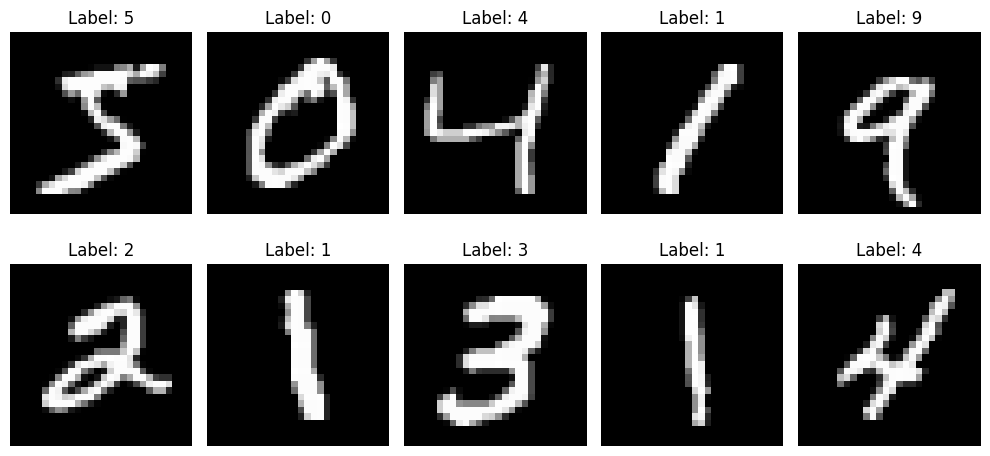

In [3]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

## Langkah 4 - Pra pengolahan data (Normalisasi)

In [4]:
x_train = x_train / 255.0
x_test = x_test / 255.0

print("Nilai Minimum:", x_train.min())
print("Nilai Maksimum:", x_train.max())
print("Shape Training:", x_train.shape)
print("Shape Testing:", x_test.shape)

Nilai Minimum: 0.0
Nilai Maksimum: 1.0
Shape Training: (60000, 28, 28)
Shape Testing: (10000, 28, 28)


## Langkah 5 – Persiapan fitur

In [5]:
x_train_flat = x_train.reshape(60000, 784)
x_test_flat = x_test.reshape(10000, 784)

print("Shape Training:", x_train_flat.shape)
print("Shape Testing:", x_test_flat.shape)

Shape Training: (60000, 784)
Shape Testing: (10000, 784)


## Langkah 6 – Membuat arsitektur ANN

In [6]:
def create_model(hidden_layers, activation):

    model = tf.keras.Sequential()

    model.add(tf.keras.layers.Input(shape=(28, 28)))

    model.add(tf.keras.layers.Flatten())

    for neurons in hidden_layers:
        model.add(
            tf.keras.layers.Dense(
                neurons,
                activation=activation
            )
        )

    model.add(
        tf.keras.layers.Dense(
            10,
            activation='softmax'
        )
    )

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

## Langkah 7 - Training dan perbandingan model

In [7]:
experiments = [
    {
        'name': 'Model 1',
        'layers': [128],
        'activation': 'relu'
    },
    {
        'name': 'Model 2',
        'layers': [128, 64],
        'activation': 'relu'
    },
    {
        'name': 'Model 3',
        'layers': [128, 64],
        'activation': 'tanh'
    }
]

results = []
trained_models = {}

for experiment in experiments:

    print("\nTraining:", experiment['name'])

    model = create_model(
        experiment['layers'],
        experiment['activation']
    )

    history = model.fit(
        x_train,
        y_train,
        epochs=5,
        batch_size=32,
        validation_split=0.1,
        verbose=1
    )

    test_loss, test_accuracy = model.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    results.append({
        'Model': experiment['name'],
        'Arsitektur': str(experiment['layers']),
        'Aktivasi': experiment['activation'],
        'Test Accuracy': test_accuracy,
        'Test Loss': test_loss,
        'History': history
    })

    trained_models[experiment['name']] = model

    print("Test Accuracy:", test_accuracy)
    print("Test Loss:", test_loss)


Training: Model 1
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - accuracy: 0.9223 - loss: 0.2718 - val_accuracy: 0.9655 - val_loss: 0.1238
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9650 - loss: 0.1196 - val_accuracy: 0.9707 - val_loss: 0.0949
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9760 - loss: 0.0821 - val_accuracy: 0.9738 - val_loss: 0.0863
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9810 - loss: 0.0606 - val_accuracy: 0.9780 - val_loss: 0.0762
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9859 - loss: 0.0456 - val_accuracy: 0.9793 - val_loss: 0.0699
Test Accuracy: 0.975600004196167
Test Loss: 0.07572442293167114

Training: Model 2
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9261 - loss: 0.2520 - val_accuracy: 0.9698 - val_loss: 0.1039
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9685 - loss: 0.1058 - val_accuracy: 0.9743 - val_loss

## Langkah 8 - Membandingkan hasil eksperimen

In [8]:
import pandas as pd

comparison = pd.DataFrame([
    {
        'Model': result['Model'],
        'Arsitektur': result['Arsitektur'],
        'Aktivasi': result['Aktivasi'],
        'Test Accuracy': result['Test Accuracy'],
        'Test Loss': result['Test Loss']
    }
    for result in results
])

print(comparison)

     Model Arsitektur Aktivasi  Test Accuracy  Test Loss
0  Model 1      [128]     relu         0.9756   0.075724
1  Model 2  [128, 64]     relu         0.9738   0.085961
2  Model 3  [128, 64]     tanh         0.9741   0.086530


## Langkah 9 - Visualisasi perbandingan akurasi

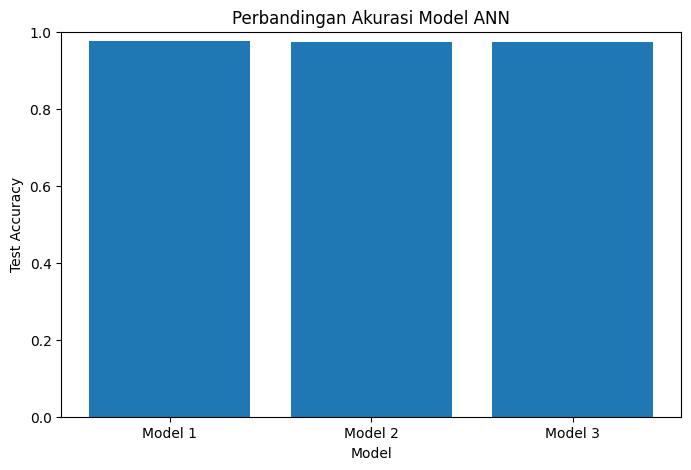

In [9]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison['Model'],
    comparison['Test Accuracy']
)

plt.title('Perbandingan Akurasi Model ANN')
plt.xlabel('Model')
plt.ylabel('Test Accuracy')
plt.ylim(0, 1)

plt.show()

## Langkah 10 - Menentukan model terbaik

In [10]:
best_result = max(
    results,
    key=lambda result: max(result['History'].history['val_accuracy'])
)

best_model = trained_models[best_result['Model']]

print("Model Terbaik:", best_result['Model'])
print("Arsitektur:", best_result['Arsitektur'])
print("Aktivasi:", best_result['Aktivasi'])
print(
    "Validation Accuracy Tertinggi:",
    max(best_result['History'].history['val_accuracy'])
)

Model Terbaik: Model 1
Arsitektur: [128]
Aktivasi: relu
Validation Accuracy Tertinggi: 0.9793333411216736


## Langkah 11 - Evaluasi model terbaik

In [11]:
test_loss, test_accuracy = best_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print("Hasil Evaluasi Model Terbaik")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

Hasil Evaluasi Model Terbaik
Test Loss: 0.07572442293167114
Test Accuracy: 0.975600004196167
Test Accuracy (%): 97.5600004196167


## Langkah 12 - Grafik Accuracy dan Loss

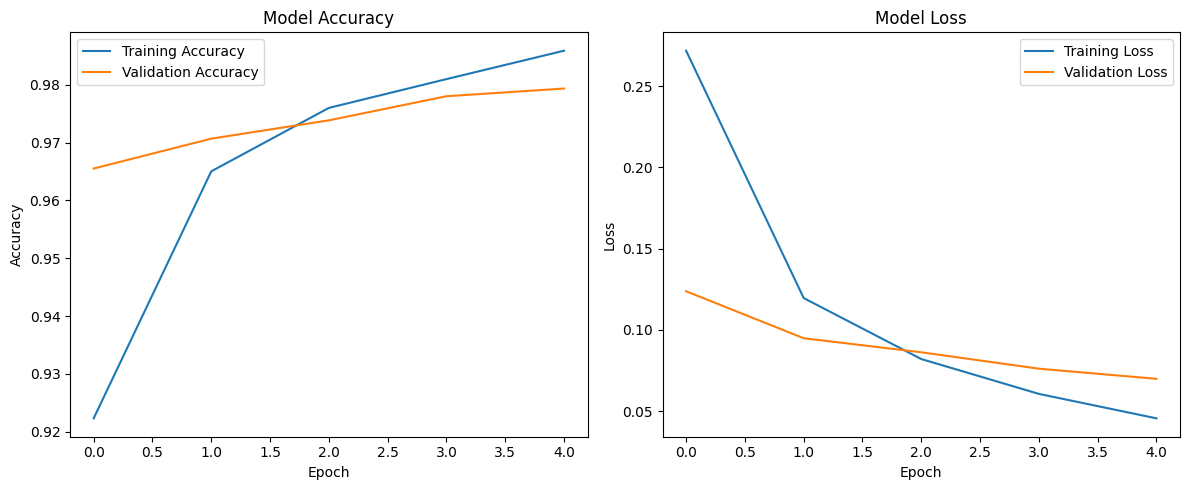

In [12]:
history = best_result['History']

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

## Langkah 13 - Confusion Matrix

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


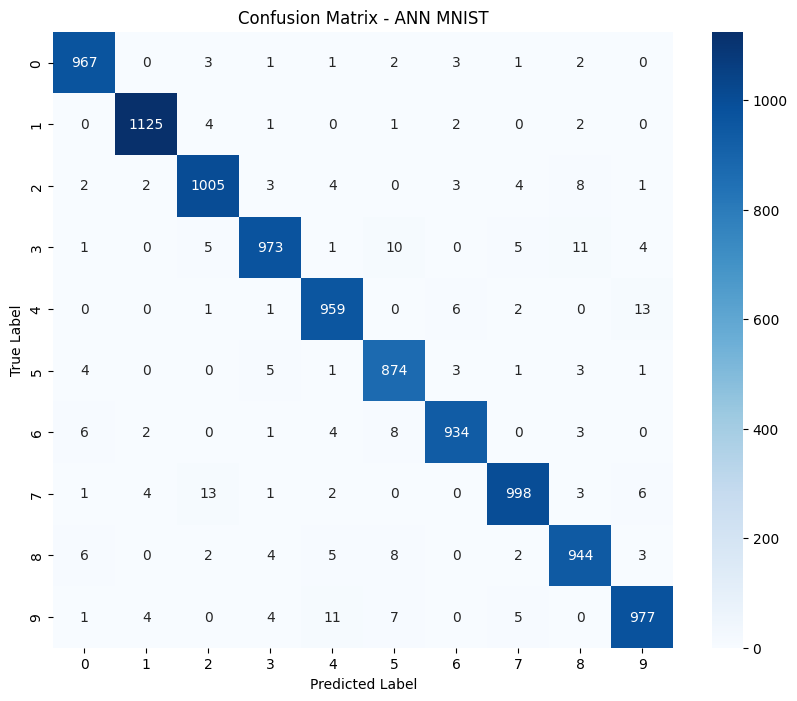

In [13]:
y_pred = best_model.predict(x_test)

y_pred_classes = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Confusion Matrix - ANN MNIST')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

## Langkah 14 - Classification Report

In [14]:
print(
    classification_report(
        y_test,
        y_pred_classes,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9787    0.9867    0.9827       980
           1     0.9894    0.9912    0.9903      1135
           2     0.9729    0.9738    0.9734      1032
           3     0.9789    0.9634    0.9711      1010
           4     0.9706    0.9766    0.9736       982
           5     0.9604    0.9798    0.9700       892
           6     0.9821    0.9749    0.9785       958
           7     0.9804    0.9708    0.9756      1028
           8     0.9672    0.9692    0.9682       974
           9     0.9721    0.9683    0.9702      1009

    accuracy                         0.9756     10000
   macro avg     0.9753    0.9755    0.9754     10000
weighted avg     0.9756    0.9756    0.9756     10000



## Langkah 15 – Pengujian prediksi gambar

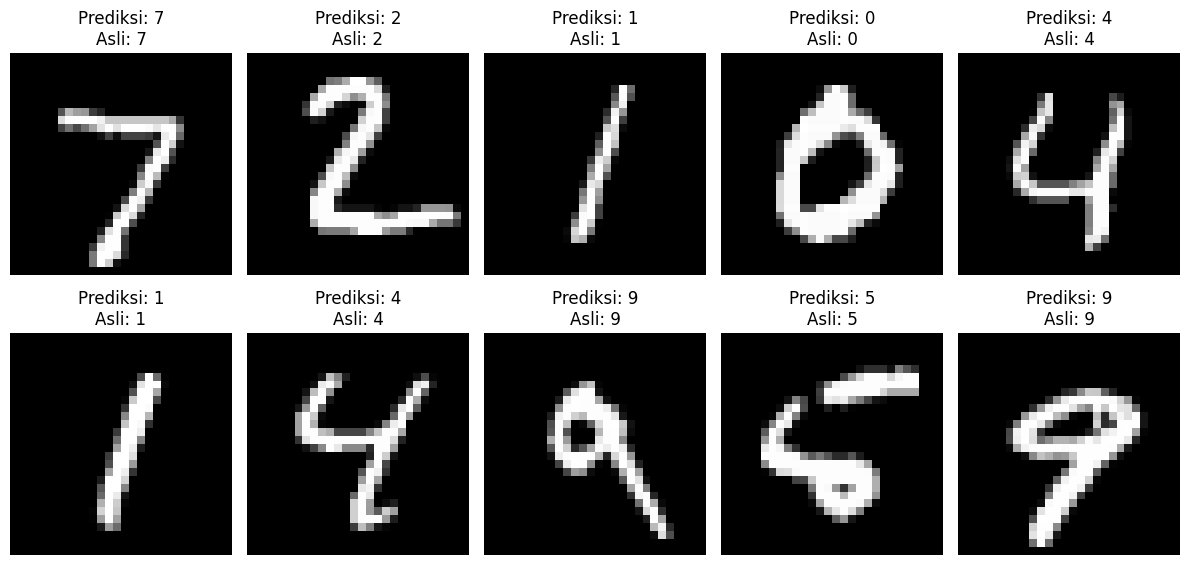

In [15]:
plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i], cmap='gray')

    prediction = y_pred_classes[i]

    actual = y_test[i]

    plt.title(
        f"Prediksi: {prediction}\nAsli: {actual}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

## Langkah 16 – Kesimpulan hasil pengujian

In [16]:
print("KESIMPULAN KLASIFIKASI MNIST")
print("--------------------------------")

print("Model Terbaik:", best_result['Model'])
print("Arsitektur:", best_result['Arsitektur'])
print("Fungsi Aktivasi:", best_result['Aktivasi'])

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)

correct = np.sum(y_pred_classes == y_test)
incorrect = np.sum(y_pred_classes != y_test)

print("Prediksi Benar:", correct)
print("Prediksi Salah:", incorrect)
print("Total Data Testing:", len(y_test))

KESIMPULAN KLASIFIKASI MNIST
--------------------------------
Model Terbaik: Model 1
Arsitektur: [128]
Fungsi Aktivasi: relu
Test Accuracy: 97.5600004196167 %
Test Loss: 0.07572442293167114
Prediksi Benar: 9756
Prediksi Salah: 244
Total Data Testing: 10000
